In [602]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")


Exploration du Dataset "Orders":

In [603]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [604]:
orders.shape
print(f"Il y a {orders.shape[0]} lignes et {orders.shape[1]} colonnes dans le dataset des commandes.")

Il y a 99441 lignes et 8 colonnes dans le dataset des commandes.


In [605]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [606]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


On constate:

5 colonnes sans valeurs manquantes.

3 colonnes présentant des valeurs manquantes.

8 colonnes interprétées comme "object", y compris les colonnes contenant des dates.

In [607]:
orders.describe(include='all')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:05:26,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-08 19:36:48,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


Les identifiants de commande (order_id) et de client (customer_id) sont uniques pour chaque ligne.

8 modalités différentes pour "order_status" avec 96478 commandes sur 99441 statuées en "delivered".

459 dates distinctes pour "order_estimated_delivery_date" sur 99441 commandes.

In [608]:
print(orders.isnull().sum())
print(f"\nIl y a {orders.isnull().sum().sum()} valeurs manquantes dans le dataset des commandes.")

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Il y a 4908 valeurs manquantes dans le dataset des commandes.


3 colonnes de dates contiennent des valeurs manquantes.

In [609]:
print(f"Il y a {orders.duplicated().sum()} lignes dupliquées dans le dataset des commandes.")

Il y a 0 lignes dupliquées dans le dataset des commandes.


Explorons la colonne "order_status" qui est la seule à ne pas être une colonne d'identification unique ou de date.

In [610]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Nous constatons 8 types d'état possibles concernant les commandes.

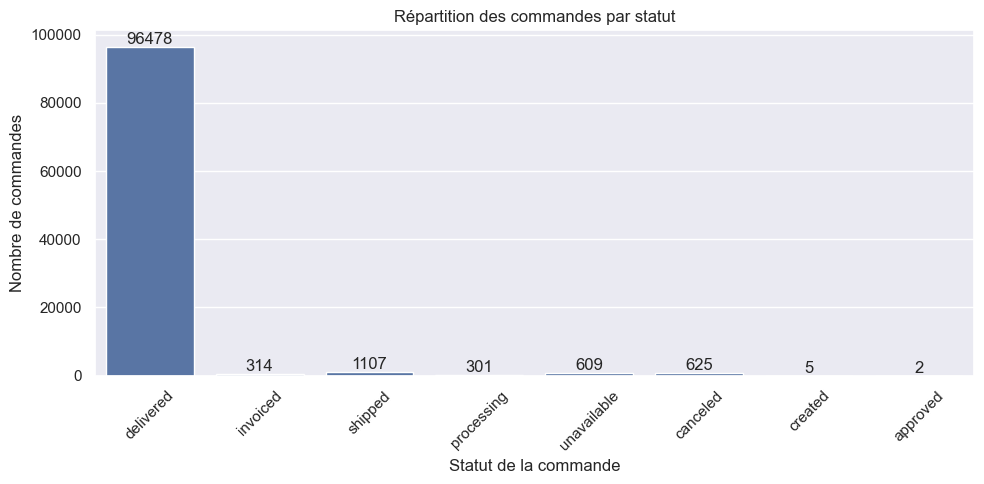

In [611]:
plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=orders,
    x="order_status"
)

ax.bar_label(ax.containers[0])

plt.xticks(rotation=45)
plt.title("Répartition des commandes par statut")
plt.xlabel("Statut de la commande")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.savefig(
    "../figures/1_repartition_commandes_statut.png",
    bbox_inches="tight"
)
plt.show()

Exploration du Dataset "Order_Reviews":

In [612]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [613]:
reviews.shape
print(f"Il y a {reviews.shape[0]} lignes et {reviews.shape[1]} colonnes dans le dataset des avis clients.")

Il y a 99224 lignes et 7 colonnes dans le dataset des avis clients.


In [614]:
reviews.columns

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='object')

In [615]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


Hormis la colonne "Review_score" en int, toutes les colonnes, y compris celles de dates, sont de type "object".

2 colonnes présentent des manquants

In [616]:
reviews.describe(include='all')

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
count,99224,99224,99224.000000,11568,40977,99224,99224
unique,98410,98673,NaN,4527,36159,636,98248
top,08528f70f579f0c830189efc523d2182,df56136b8031ecd28e200bb18e6ddb2e,NaN,Recomendo,Muito bom,2017-12-19 00:00:00,2017-06-15 23:21:05
freq,3,3,NaN,423,230,463,4
mean,NaN,NaN,4.086421,NaN,NaN,NaN,NaN
std,NaN,NaN,1.347579,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN


"review_id" et "order_id" présentent respectivement 98 410 et 98 673 valeurs uniques pour 99 224 lignes. Certains identifiants apparaissent donc plusieurs fois.

Très peu d'informations sont présentes dans "review_comment_title" puisque seulement 11 568 avis sur 99 224 contiennent un titre.

"review_comment_message" contient 40 977 commentaires pour 99 224 avis. Une majorité des clients attribue donc uniquement une note sans laisser de commentaire.

"review_creation_date" ne contient que 636 dates distinctes alors que le dataset comporte 99 224 avis: de nombreux avis sont créés le même jour.


In [617]:
print(reviews.isnull().sum())
print(f"\nIl y a {reviews.isnull().sum().sum()} valeurs manquantes dans le dataset des avis clients.")

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Il y a 145903 valeurs manquantes dans le dataset des avis clients.


Les identifiants, les notes et les dates ne présentent aucune valeur manquante.

Les commentaires étant facultatifs, ces absences peuvent correspondre à des avis déposés sans commentaire écrit. 

In [618]:
print(f"Il y a {reviews.duplicated().sum()} lignes dupliquées dans le dataset des commandes.")

Il y a 0 lignes dupliquées dans le dataset des commandes.


Explorons donc la colonne "review_score" qui contient les notes et commentaires des clients:

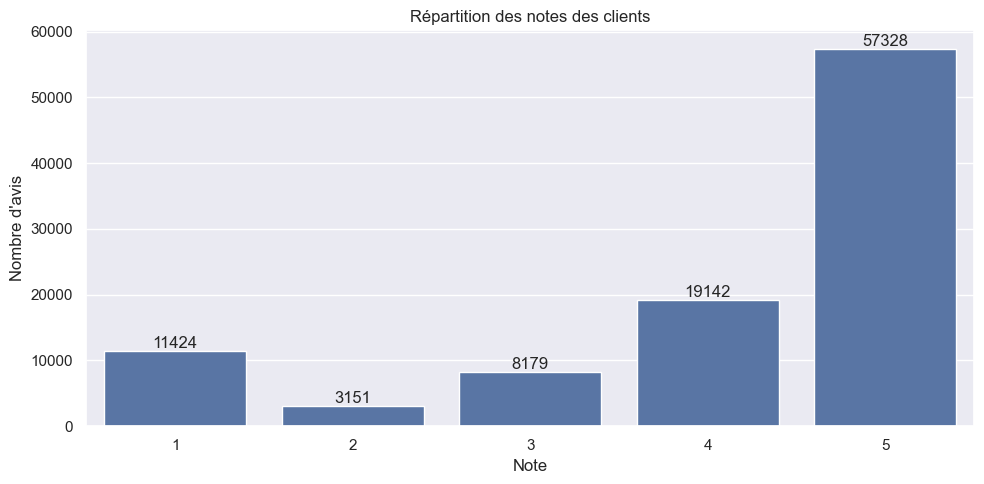

In [619]:
plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=reviews,
    x="review_score"
)

ax.bar_label(ax.containers[0])

plt.title("Répartition des notes des clients")
plt.xlabel("Note")
plt.ylabel("Nombre d'avis")

plt.tight_layout()
plt.savefig(
    "../figures/2_repartition_notes_clients.png",
    bbox_inches="tight"
)
plt.show()

Conclusion:


Le dataset "Orders" contient 99 441 commandes réparties sur 8 colonnes.

Les identifiants de commande "order_id" sont uniques, ce qui confirme que chaque ligne correspond à une commande distincte.

Le statut "delivered" est largement majoritaire.

Plusieurs colonnes de dates sont actuellement interprétées comme du texte (object) et devront être converties au format datetime lors de la phase de nettoyage.

Des valeurs manquantes ont été identifiées dans certaines colonnes liées à la validation et à la livraison des commandes.


Le dataset Reviews contient 99 224 avis clients répartis sur 7 colonnes.

Les colonnes review_id et order_id ne sont pas totalement uniques, certains identifiants apparaissant plusieurs fois.

La note moyenne attribuée par les clients est de 4,09 sur 5.

Seule une minorité des clients laisse un titre ou un commentaire écrit, la plupart se limitant à attribuer une note.

Enfin, les deux datasets possèdent la colonne order_id, qui pourra être utilisée comme clé de jointure lors de la phase d'analyse.